<a href="https://colab.research.google.com/github/Penguinboy1990/Machine-Learning/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Diabetes Classification using Ensemble Learning and Random Forests

1. Loads the dataset into a Pandas DataFrame.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier
df = pd.read_csv('indians_dabetes_uci.csv')

2. Uses inspection methods (head(), info(), and describe()) to analyze features.

In [4]:
print('\nHead Method: ')
print(df.head())

print('\nInfo Method: ')
print(df.info())

print('\nDescribe Method: ')
print(df.describe())


Head Method: 
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Info Method: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1  

3. Quantify and handle implicit missing values using SimpleImputer.

In [5]:
# Physiological columns where 0 is an invalid placeholder
cols_with_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Quantifies missing values (zeros)
print("\nMissing Values: ")
print((df[cols_with_zeros] == 0).sum())

# Replaces 0s with NaN
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

# Remove Outcome
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

# Training Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=35, stratify=y)


Missing Values: 
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


4. Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

In [6]:
# Use median imputation for missing values and standard scaling
# The preprocessing is fitted on the training data within each pipeline.
numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),])
preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, X.columns)])

5. Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use must use appropriate plots to show the results.


Voting Classifier Results

Hard Voting Test Accuracy:  0.8312

Soft Voting Test Accuracy:  0.8442

Hard Voting Classification Report
              precision    recall  f1-score   support

           0       0.85      0.90      0.87       100
           1       0.79      0.70      0.75        54

    accuracy                           0.83       154
   macro avg       0.82      0.80      0.81       154
weighted avg       0.83      0.83      0.83       154


Soft Voting Classification Report
              precision    recall  f1-score   support

           0       0.86      0.91      0.88       100
           1       0.81      0.72      0.76        54

    accuracy                           0.84       154
   macro avg       0.84      0.82      0.82       154
weighted avg       0.84      0.84      0.84       154



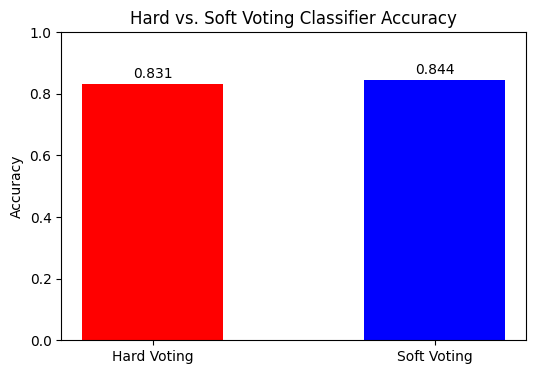

In [9]:
clf1 = LogisticRegression(random_state=35)
clf2 = SVC(probability=True, random_state=35)
clf3 = DecisionTreeClassifier(random_state=35)

hard_voting = VotingClassifier(estimators=[("lr", clf1), ("svc", clf2), ("dt", clf3)], voting="hard")
soft_voting = VotingClassifier(estimators=[("lr", clf1), ("svc", clf2), ("dt", clf3)], voting="soft")

# Wraps the preprocessor and classifiers into pipelines
hard_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", hard_voting)])
soft_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", soft_voting)])

hard_pipeline.fit(X_train, y_train)
soft_pipeline.fit(X_train, y_train)

y_pred_hard = hard_pipeline.predict(X_test)
y_pred_soft = soft_pipeline.predict(X_test)

print("\nVoting Classifier Results")
print("\nHard Voting Test Accuracy: ", np.round(accuracy_score(y_test, y_pred_hard),4))
print("\nSoft Voting Test Accuracy: ", np.round(accuracy_score(y_test, y_pred_soft),4))

print("\nHard Voting Classification Report")
print(classification_report(y_test, y_pred_hard, zero_division=0))

print("\nSoft Voting Classification Report")
print(classification_report(y_test, y_pred_soft, zero_division=0))

# Plot Voting Results
voting_accs = [accuracy_score(y_test, y_pred_hard), accuracy_score(y_test, y_pred_soft),]
plt.figure(figsize=(6, 4))
plt.bar(["Hard Voting", "Soft Voting"], voting_accs, color=["red", "blue"], width=0.5)
plt.ylabel("Accuracy")
plt.ylim(0, 1.0)
plt.title("Hard vs. Soft Voting Classifier Accuracy")
for i, v in enumerate(voting_accs):
    plt.text(i, v + 0.02, np.round(v,3), ha="center")
plt.show()

6. Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph


Bagging Classifier

OOB Score:  0.8909
Test Accuracy:  0.8571


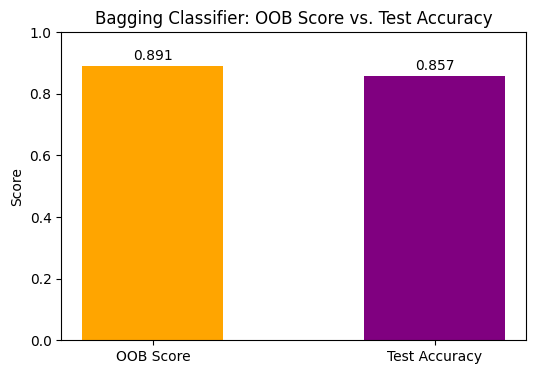

In [13]:
bagging_pipe = Pipeline(steps=[("preprocessor", preprocessor),
 ("bagging", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=35), n_estimators=100, bootstrap=True, oob_score=True, random_state=35))])

bagging_pipe.fit(X_train, y_train)
oob_score = bagging_pipe.named_steps["bagging"].oob_score_
test_acc_bagging = accuracy_score(y_test, bagging_pipe.predict(X_test))

print("\nBagging Classifier")
print("\nOOB Score: ", np.round(oob_score, 4))
print("Test Accuracy: ", np.round(test_acc_bagging,4))

# Plots OOB vs Test Accuracy
plt.figure(figsize=(6, 4))
plt.bar(["OOB Score", "Test Accuracy"], [oob_score, test_acc_bagging], color=["orange", "purple"], width=0.5)
plt.ylabel("Score")
plt.ylim(0, 1.0)
plt.title("Bagging Classifier: OOB Score vs. Test Accuracy")
for i, v in enumerate([oob_score, test_acc_bagging]):
    plt.text(i, v + 0.02, np.round(v,3), ha="center")
plt.show()

7. Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).


Random Forest: 
Test Accuracy:  0.8701


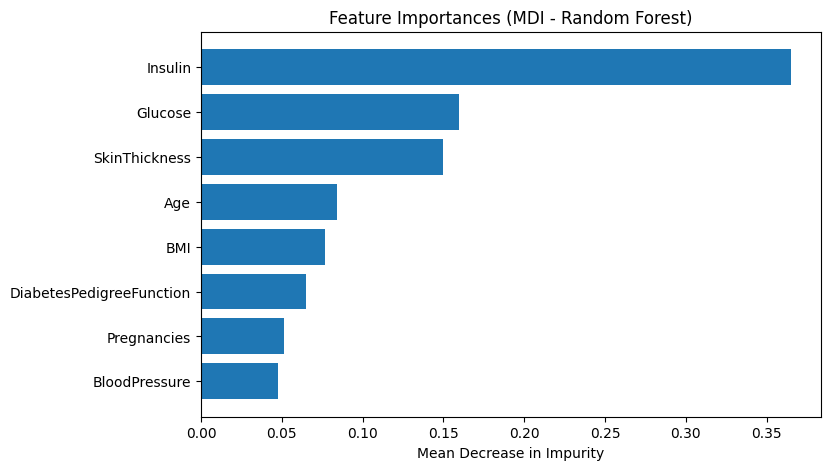

In [14]:
rf_pipe = Pipeline(steps=[("preprocessor", preprocessor), ("rf", RandomForestClassifier(n_estimators=100, max_features="sqrt", random_state=35))])

rf_pipe.fit(X_train, y_train)
test_acc_rf = accuracy_score(y_test, rf_pipe.predict(X_test))
print("\nRandom Forest: ")
print("Test Accuracy: ", np.round(test_acc_rf,4))

importances = rf_pipe.named_steps["rf"].feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 5))
plt.title("Feature Importances (MDI - Random Forest)")
plt.barh(range(X.shape[1]), importances[indices], align="center")
plt.yticks(range(X.shape[1]), [X.columns[i] for i in indices])
plt.xlabel("Mean Decrease in Impurity")
plt.show()

8. Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results


AdaBoost
Final Training Accuracy:  0.9153
Final Test Accuracy:  0.8506


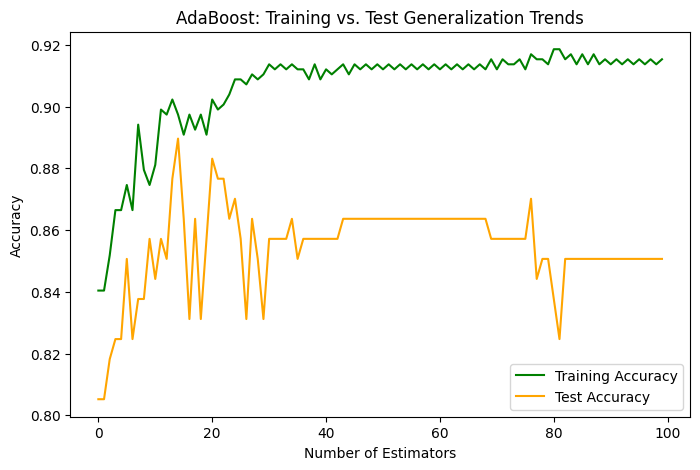

In [17]:
adaboost_pipe = Pipeline(steps=[("preprocessor", preprocessor),
 ("ada", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=35), n_estimators=100, random_state=35,))])

adaboost_pipe.fit(X_train, y_train)

# Evaluates training vs test performance across boosting iterations using staged scoring
X_train_processed = adaboost_pipe.named_steps["preprocessor"].transform(X_train)
X_test_processed = adaboost_pipe.named_steps["preprocessor"].transform(X_test)

ada_model = adaboost_pipe.named_steps["ada"]
train_staged_scores = list(ada_model.staged_score(X_train_processed, y_train))
test_staged_scores = list(ada_model.staged_score(X_test_processed, y_test))

ada_train_accuracy = accuracy_score(y_train, adaboost_pipe.predict(X_train))

ada_test_accuracy = accuracy_score(y_test, adaboost_pipe.predict(X_test))

print("\nAdaBoost")
print("Final Training Accuracy: ", np.round(ada_train_accuracy,4))
print("Final Test Accuracy: ", np.round(ada_test_accuracy,4))

plt.figure(figsize=(8, 5))
plt.plot(train_staged_scores, label="Training Accuracy", color="green")
plt.plot(test_staged_scores, label="Test Accuracy", color="orange")
plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Training vs. Test Generalization Trends")
plt.legend()
plt.show()